# Analisis Numerik
## Perhitungan Volume Kedua Lambung Perahu Katamaran

Nama:Kasnanda Holymapah Siagian

NPM: 25083010039

Kelas: A  

Mata Kuliah: Analisis Numerik



Notebook ini menghitung perkiraan volume masing-masing lambung dari luas penampang pada beberapa posisi sepanjang kapal. Perhitungan memakai asumsi penampang persegi panjang, mengabaikan *reserve buoyancy*, dan membandingkan aturan trapesium dengan Simpson 1/3.

## 1. Model matematika

Luas penampang pada titik ke-\(i\) dihitung dari lebar dan tinggi penampang. Dengan asumsi penampang berbentuk persegi panjang, rumus luasnya adalah:

$$
A_i=b_i\times h_i
$$

Volume lambung kapal diperoleh dari integral luas penampang sepanjang kapal:

$$
V=\int_0^L A(x)\,dx
$$

Karena luas penampang hanya diketahui pada beberapa titik pengukuran, integral dihampiri menggunakan metode numerik.

### Metode trapesium

$$
V\approx\sum_{i=0}^{n-1}
\frac{A_i+A_{i+1}}{2}(x_{i+1}-x_i)
$$

### Metode Simpson 1/3

Untuk jarak antartitik yang seragam dan jumlah interval genap, digunakan rumus:

$$
V\approx\frac{\Delta x}{3}
\left[
A_0+A_n+
4\sum_{\substack{i=1\\i\text{ ganjil}}}^{n-1}A_i+
2\sum_{\substack{i=2\\i\text{ genap}}}^{n-2}A_i
\right]
$$

Keterangan: \(A_i\) adalah luas penampang, \(x_i\) adalah posisi penampang sepanjang kapal, \(\Delta x\) adalah jarak seragam antartitik, dan \(n\) adalah jumlah interval.

## 2. Skala dan data posisi

Skala kerja yang digunakan pada notebook ini adalah $1$ kotak $=45$ cm $=0{,}45$ m. Data lebar dan tinggi diubah ke meter sebelum luas penampang dihitung.

**Catatan data:** angka di bawah merupakan nilai perkiraan yang tercantum pada notebook acuan, bukan pembacaan grid yang telah diverifikasi dari gambar tugas. Panjang efektif 6,92 m dan semua ukuran harus diperiksa kembali terhadap gambar asli sebelum hasil dipakai sebagai jawaban final.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

M_PER_KOTAK = 0.45
PANJANG_M = 6.92
JUMLAH_INTERVAL = 32

# Data perkiraan dalam satuan kotak; verifikasi dengan gambar soal.
lebar1_kotak = np.array([
    1.627, 1.716, 1.796, 1.849, 1.902, 1.938, 1.956, 1.973, 1.982,
    1.982, 1.982, 1.991, 1.982, 1.991, 1.982, 1.991, 1.991, 1.991,
    1.991, 1.991, 1.991, 1.991, 1.982, 1.973, 1.956, 1.911, 1.867,
    1.796, 1.724, 1.627, 1.502, 1.376, 1.216
])

lebar2_kotak = np.array([
    1.618, 1.716, 1.787, 1.849, 1.893, 1.938, 1.964, 1.982, 1.991,
    1.991, 1.991, 1.991, 1.991, 1.991, 1.991, 1.991, 1.991, 1.991,
    1.991, 1.991, 1.991, 1.991, 1.982, 1.973, 1.947, 1.911, 1.858,
    1.796, 1.716, 1.618, 1.502, 1.367, 1.207
])

tinggi_kotak = np.array([
    1.629, 1.824, 1.987, 2.133, 2.253, 2.342, 2.342, 2.342, 2.342,
    2.342, 2.338, 2.333, 2.329, 2.338, 2.333, 2.333, 2.333, 2.333,
    2.333, 2.329, 2.324, 2.329, 2.324, 2.324, 2.324, 2.324, 2.324,
    2.324, 2.324, 2.324, 2.320, 2.320, 2.316
])

posisi = np.linspace(0, PANJANG_M, JUMLAH_INTERVAL + 1)
dx = posisi[1] - posisi[0]

lebar1 = lebar1_kotak * M_PER_KOTAK
lebar2 = lebar2_kotak * M_PER_KOTAK
tinggi = tinggi_kotak * M_PER_KOTAK

print(f"Jumlah posisi: {len(posisi)}")
print(f"Panjang efektif sementara: {PANJANG_M:.2f} m")
print(f"Jarak antarposisi: {dx:.5f} m")

Jumlah posisi: 33
Panjang efektif sementara: 6.92 m
Jarak antarposisi: 0.21625 m


## 3. Pemeriksaan konsistensi data

Sebelum menghitung volume, panjang setiap array harus sama dengan jumlah posisi. Pemeriksaan ini mendeteksi ketidaksesuaian bentuk data, tetapi tidak dapat memastikan bahwa ukuran perkiraan sudah tepat terhadap gambar.

In [2]:
assert len(posisi) == len(lebar1) == len(lebar2) == len(tinggi)
assert np.isfinite(np.r_[posisi, lebar1, lebar2, tinggi]).all()
assert np.all(np.diff(posisi) > 0)
assert np.all(lebar1 >= 0) and np.all(lebar2 >= 0) and np.all(tinggi >= 0)
assert np.allclose(np.diff(posisi), dx)
assert (len(posisi) - 1) % 2 == 0

print("Pemeriksaan struktur data berhasil.")
print(f"Jumlah interval: {len(posisi) - 1}")

Pemeriksaan struktur data berhasil.
Jumlah interval: 32


## 4. Menghitung luas penampang

Karena penampang dianggap persegi panjang, luas kedua lambung dihitung secara terpisah. Tinggi penampang digunakan bersama, sedangkan lebar tiap lambung mempunyai data masing-masing.

In [3]:
luas1 = lebar1 * tinggi
luas2 = lebar2 * tinggi

tabel_penampang = pd.DataFrame({
    "Posisi ke": np.arange(len(posisi)),
    "Jarak (m)": posisi,
    "Lebar lambung 1 (m)": lebar1,
    "Lebar lambung 2 (m)": lebar2,
    "Tinggi (m)": tinggi,
    "Luas lambung 1 (m²)": luas1,
    "Luas lambung 2 (m²)": luas2
})

display(tabel_penampang.round(4))

,Posisi ke,Jarak (m),Lebar lambung 1 (m),Lebar lambung 2 (m),Tinggi (m),Luas lambung 1 (m²),Luas lambung 2 (m²)
0,0,0.0000,0.7322,0.7281,0.7330,0.5367,0.5337
1,1,0.2162,0.7722,0.7722,0.8208,0.6338,0.6338
2,2,0.4325,0.8082,0.8042,0.8942,0.7227,0.7190
3,3,0.6487,0.8320,0.8320,0.9598,0.7986,0.7986
4,4,0.8650,0.8559,0.8518,1.0139,0.8678,0.8636
5,5,1.0812,0.8721,0.8721,1.0539,0.9191,0.9191
6,6,1.2975,0.8802,0.8838,1.0539,0.9276,0.9314
7,7,1.5138,0.8878,0.8919,1.0539,0.9357,0.9400
8,8,1.7300,0.8919,0.8960,1.0539,0.9400,0.9442
9,9,1.9462,0.8919,0.8960,1.0539,0.9400,0.9442


## 5. Fungsi integrasi numerik

Aturan trapesium menghubungkan dua luas penampang yang berdekatan. Simpson 1/3 menggunakan bobot 1, 4, dan 2 secara bergantian; metode ini hanya digunakan karena posisi pada data ini dibuat berjarak seragam dan jumlah intervalnya genap.

In [4]:
def integrasi_trapesium(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if len(x) != len(y) or len(x) < 2:
        raise ValueError("x dan y harus sama panjang dan minimal dua titik.")
    if not np.all(np.diff(x) > 0):
        raise ValueError("Posisi x harus berurutan naik.")
    return np.sum(np.diff(x) * (y[:-1] + y[1:]) / 2)


def integrasi_simpson13(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    selisih = np.diff(x)

    if len(x) != len(y) or len(x) < 3:
        raise ValueError("Diperlukan minimal tiga titik dengan panjang data sama.")
    if not np.allclose(selisih, selisih[0]):
        raise ValueError("Simpson 1/3 memerlukan jarak yang seragam.")

    n = len(x) - 1
    if n % 2 != 0:
        raise ValueError("Simpson 1/3 memerlukan jumlah interval genap.")

    h = selisih[0]
    return h / 3 * (
        y[0] + y[-1]
        + 4 * np.sum(y[1:-1:2])
        + 2 * np.sum(y[2:-1:2])
    )

## 6. Hasil volume dari dua metode

Luas penampang diintegralkan terhadap posisi untuk memperoleh volume setiap lambung. Hasil kedua metode ditampilkan berdampingan agar perbedaan pendekatan numeriknya dapat dilihat.

In [5]:
hasil = {
    "Trapesium": [
        integrasi_trapesium(posisi, luas1),
        integrasi_trapesium(posisi, luas2)
    ],
    "Simpson 1/3": [
        integrasi_simpson13(posisi, luas1),
        integrasi_simpson13(posisi, luas2)
    ]
}

tabel_hasil = pd.DataFrame(
    hasil,
    index=["Lambung 1 (m³)", "Lambung 2 (m³)"]
)
display(tabel_hasil.round(6))

print(f"Total kedua lambung (trapesium): {sum(hasil['Trapesium']):.6f} m³")
print(f"Total kedua lambung (Simpson 1/3): {sum(hasil['Simpson 1/3']):.6f} m³")

,Trapesium,Simpson 1/3
Lambung 1 (m³),6.021046,6.025864
Lambung 2 (m³),6.020470,6.025490


Total kedua lambung (trapesium): 12.041516 m³
Total kedua lambung (Simpson 1/3): 12.051354 m³


## 7. Perincian volume per segmen

Tabel berikut menunjukkan kontribusi setiap interval pada volume hasil aturan trapesium. Penjumlahan kolom kontribusi volume akan menghasilkan volume masing-masing lambung dengan metode tersebut.

In [6]:
delta_x = np.diff(posisi)

segmen1 = delta_x * (luas1[:-1] + luas1[1:]) / 2
segmen2 = delta_x * (luas2[:-1] + luas2[1:]) / 2

rincian = pd.DataFrame({
    "Segmen": np.arange(1, len(delta_x) + 1),
    "Posisi awal (m)": posisi[:-1],
    "Posisi akhir (m)": posisi[1:],
    "Volume lambung 1 (m³)": segmen1,
    "Volume lambung 2 (m³)": segmen2
})
display(rincian.round(5))

,Segmen,Posisi awal (m),Posisi akhir (m),Volume lambung 1 (m³),Volume lambung 2 (m³)
0,1,0.00000,0.21625,0.12656,0.12624
1,2,0.21625,0.43250,0.14667,0.14628
2,3,0.43250,0.64875,0.16449,0.16410
3,4,0.64875,0.86500,0.18018,0.17974
4,5,0.86500,1.08125,0.19320,0.19276
5,6,1.08125,1.29750,0.19968,0.20009
6,7,1.29750,1.51375,0.20147,0.20235
7,8,1.51375,1.73000,0.20281,0.20373
8,9,1.73000,1.94625,0.20327,0.20419
9,10,1.94625,2.16250,0.20310,0.20402


## 8. Grafik luas penampang

Grafik berikut memperlihatkan perubahan luas penampang sepanjang posisi kapal. Grafik ini membantu melihat bagian lambung yang luas penampangnya lebih besar maupun lebih kecil.

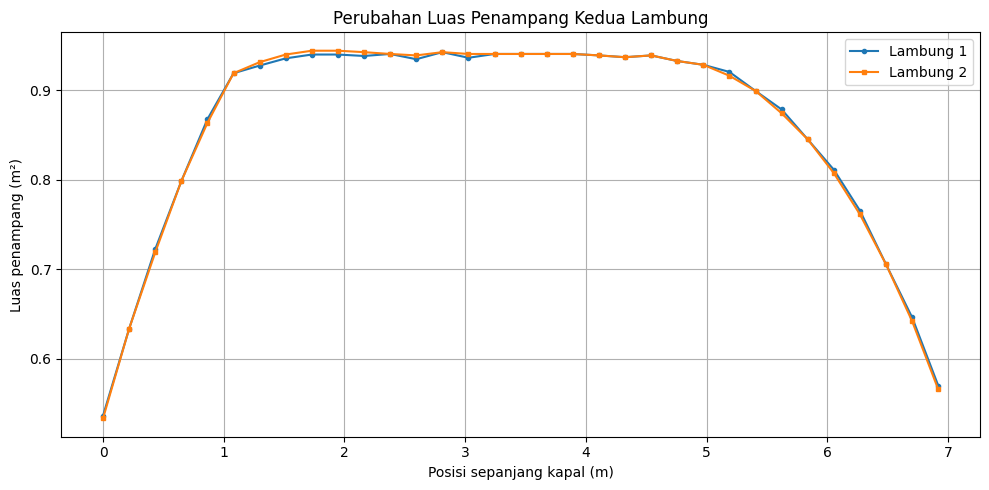

In [7]:
plt.figure(figsize=(10, 5))
plt.plot(posisi, luas1, marker="o", markersize=3, label="Lambung 1")
plt.plot(posisi, luas2, marker="s", markersize=3, label="Lambung 2")
plt.xlabel("Posisi sepanjang kapal (m)")
plt.ylabel("Luas penampang (m²)")
plt.title("Perubahan Luas Penampang Kedua Lambung")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 9. Kesimpulan

Volume kedua lambung diperkirakan dengan mengintegralkan luas penampang sepanjang kapal. Aturan trapesium dan Simpson 1/3 memberikan dua pendekatan numerik yang dapat dibandingkan. Perhitungan mengikuti asumsi penampang persegi panjang dan tidak memasukkan volume *reserve buoyancy*.

**Validitas hasil bergantung pada data masukan.** Ukuran penampang dan panjang efektif pada notebook ini masih berupa perkiraan yang belum diverifikasi dari gambar soal. Karena itu, angka volume yang tampil bersifat sementara dan perlu dihitung ulang setelah pengukuran gambar dikonfirmasi.